In [94]:
from dotenv import load_dotenv
import os
load_dotenv()

True

In [95]:
EXCHANGE_RATE_KEY = os.getenv('EXCHANGE_RATE_API_KEY')

In [96]:
from langchain_core.tools import tool
import requests

@tool(
    description="""
    Get the currency conversion rate between a base currency and target currency.
    Use this tool first when a user asks to convert currencies. Pass its
    conversion rate result to the convert tool.
    """
)
def get_conversion_factor(base_currency: str, target_currency: str) -> float:
    
    url = f'https://v6.exchangerate-api.com/v6/{EXCHANGE_RATE_KEY}/pair/{base_currency}/{target_currency}'
    
    raw_result = requests.get(url)
    data = raw_result.json()
    return data['conversion_rate']

@tool(
    description="""
    Convert a currency amount using a conversion rate obtained from
    get_conversion_factor. Use this tool after getting the conversion rate.
    """
)
def convert(base_currency_value: float, conversion_rate: float) -> float:
    return base_currency_value * conversion_rate

In [97]:
from langchain_groq import ChatGroq

llm = ChatGroq(model='openai/gpt-oss-120b',max_tokens=200,temperature=0.1)

llm_with_tools = llm.bind_tools([get_conversion_factor,convert])

In [98]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt.tool_node import ToolNode, tools_condition
from langgraph.graph.message import MessagesState
from langchain.messages import HumanMessage
from typing import Annotated

In [99]:
def chat_node(state,config):
    response = llm_with_tools.invoke(state['messages'])
    return {
        "messages": [response]
    }

In [100]:
graph = StateGraph(MessagesState)

graph.add_node('chat_node', chat_node)
graph.add_node('tools',ToolNode([get_conversion_factor,convert]))

graph.add_edge(START, "chat_node")

graph.add_conditional_edges(
    "chat_node",
    tools_condition
)

graph.add_edge("tools", "chat_node")

workflow = graph.compile()

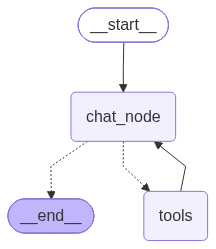

In [101]:
from IPython.display import display, Image
display(Image(workflow.get_graph().draw_mermaid_png()))

In [102]:
result = workflow.invoke({
    "messages": [
        HumanMessage(
            content="What is the currency conversion rate between USD and INR?"
        )
    ]
})

In [103]:
result

{'messages': [HumanMessage(content='What is the currency conversion rate between USD and INR?', additional_kwargs={}, response_metadata={}, id='a5f71bd1-ab89-4c04-a013-d652be429688'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "What is the currency conversion rate between USD and INR?" We need to get conversion factor using get_conversion_factor. Then respond with rate. Use function.', 'tool_calls': [{'id': 'fc_442a9932-0f94-4914-abbb-eac53be72b15', 'function': {'arguments': '{"base_currency":"USD","target_currency":"INR"}', 'name': 'get_conversion_factor'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 73, 'prompt_tokens': 217, 'total_tokens': 290, 'completion_time': 0.152516259, 'completion_tokens_details': {'reasoning_tokens': 35}, 'prompt_time': 0.008821272, 'prompt_tokens_details': None, 'queue_time': 0.348809303, 'total_time': 0.161337531}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4200b3f836',